# 01 · A yardstick for unseen domains
**Report sections:** Generalization & error analysis (Q4), Open-ended improvement (Q5)

**The problem.** Our validation set is a random 20% of `train.csv`, so it contains the same kinds of text
as the training rows. The team's best model scores 0.991 there but 0.913 on Kaggle. Validation is not
telling us how a model behaves on text it has not seen before.

**What this notebook does.** It builds two extra tests on the *same* shared 2,000 validation rows:

1. **Unseen domain** - group the texts by topic, then score each validation text with a model that was
   trained without that topic.
2. **Layout removed** - collapse line breaks and extra spaces in the validation texts, so a model cannot
   lean on formatting.

**Findings (numbers are in the tables below).**
- **Every team model is weaker on a topic it did not train on.** Baseline: 0.956 -> 0.903. Allen's tuned SVM: 0.979 -> 0.933.
  Film reviews, biographies, news and personal posts lose 0.06-0.11 AUROC; recipes lose almost nothing.
- **It is the missing topic, not the smaller training set.** Removing the same number of rows at random leaves the baseline at 0.955.
- **Standard validation ranks the models wrongly.** `logreg_all` (layout + style features) scores 0.980, above the baseline,
  but falls to 0.700 when layout is removed. On Kaggle it is below the baseline (0.804 vs 0.860).
- **The strictest test (unseen domain + layout removed) puts the three models with a known Kaggle score in the same order as Kaggle:**
  0.745 < 0.903 < 0.933 versus 0.804 < 0.860 < 0.913. Three models is a hint, not proof.

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)   # harmless matmul warnings from scaled style features

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test, load_unlabeled
from src.models import make_model
from src.evaluate import log_result, savefig

from domain_eval import TopicDomains, domain_stress_test
from plots import plot_stress_summary, plot_domain_drop

set_seed(SEED)
pd.set_option("display.max_colwidth", 90)

## Data
Same shared split as everyone on the team: 8,000 training rows / 2,000 validation rows, seed 42.

In [3]:
train_df, val_df = get_split()
test_df = load_test()
unl_df = load_unlabeled()

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


[unlabeled] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


## Step 1 · Group the texts into topics ("domains")
We do not have domain labels, so we make our own. Each training text becomes a vector of its content
words (TF-IDF, stop words removed), is squeezed to 100 numbers (SVD), and k-means puts similar texts into
`k = 8` groups. **No human/AI labels are used here**, and the groups are fitted on the 8,000 training rows only.

In [4]:
domains = TopicDomains(k=8).fit(train_df["text"])
dom_train = domains.predict(train_df["text"])
dom_val = domains.predict(val_df["text"])

domains.describe(train_df["text"], train_df["label"]).round(3)

,domain,n,share,ai_share,typical_words
0,0,1562,0.195,0.503,"ve, like, just, know, don, feel, really, want"
1,1,1518,0.190,0.511,"said, year, company, album, mr, uk, government, world"
2,2,799,0.100,0.506,"properties, study, quantum, systems, results, theory, paper, finite"
3,3,865,0.108,0.503,"pepper, cup, chopped, oil, salt, heat, garlic, add"
4,4,573,0.072,0.489,"film, movie, br, story, characters, movies, films, character"
5,5,942,0.118,0.505,"segmentation, image, images, learning, method, methods, proposed, approach"
6,6,681,0.085,0.476,"sugar, cup, flour, butter, baking, bowl, vanilla, minutes"
7,7,1060,0.132,0.492,"born, university, career, american, school, member, served, known"


**How to read this.** `typical_words` shows what each group is about. `ai_share` near 0.5 matters: it means a
group is a *topic*, not a hidden copy of the label, so AUROC inside a group is meaningful.

In [5]:
# How common is each domain in the other files, and how well do those files fit our 8 topics?
sets = {"train": train_df, "val": val_df, "unlabeled": unl_df, "test": test_df}
shares = pd.DataFrame({name: pd.Series(domains.predict(d["text"])).value_counts(normalize=True).sort_index()
                       for name, d in sets.items()})
shares.index = domains.names_
display(shares.round(3))

fit = pd.Series({name: domains.fit_quality(d["text"]).mean() for name, d in sets.items()})
print("Mean similarity to the nearest topic centre (higher = fits the training topics better):")
print(fit.round(3).to_string())

,train,val,unlabeled,test
"d0: ve, like, just",0.195,0.197,0.199,0.291
"d1: said, year, company",0.190,0.178,0.180,0.218
"d2: properties, study, quantum",0.100,0.096,0.095,0.063
"d3: pepper, cup, chopped",0.108,0.102,0.117,0.072
"d4: film, movie, br",0.072,0.073,0.076,0.103
"d5: segmentation, image, images",0.118,0.116,0.123,0.071
"d6: sugar, cup, flour",0.085,0.094,0.078,0.046
"d7: born, university, career",0.132,0.144,0.131,0.136


Mean similarity to the nearest topic centre (higher = fits the training topics better):
train        0.600
val          0.646
unlabeled    0.653
test         0.597


## Step 2 · The stress test
For one model configuration, `domain_stress_test` reports four AUROCs on the 2,000 validation rows:

| name | training data | validation text |
|---|---|---|
| `val_auroc` | all 8,000 rows | unchanged (this is the team's usual number) |
| `val_layout_removed` | all 8,000 rows | line breaks / extra spaces collapsed |
| `unseen_domain_mean` | everything **except** the text's own domain | unchanged |
| `unseen_layout_removed_mean` | everything except the text's own domain | collapsed |

The two "unseen" numbers are the average of the 8 per-domain AUROCs (one model is trained per held-out domain).

**Fairness check.** Holding out a domain also shrinks the training set. With `size_control=True` we also train
models with the same number of rows removed *at random*. If those stay good, the drop is caused by the
missing domain, not by less data. We run this check once, on the baseline.

In [6]:
t0 = time.time()
base_summary, base_domains, base_preds = domain_stress_test(
    lambda: make_model("baseline"), train_df, val_df, dom_train, dom_val, size_control=True)
print(f"done in {time.time() - t0:.0f}s")

base_domains.assign(domain=lambda d: d["domain"].map(lambda i: domains.names_[i])).round(4)

  domain 0: seen 0.9572 -> unseen 0.8864


  domain 1: seen 0.9034 -> unseen 0.8297


  domain 2: seen 0.9197 -> unseen 0.8992


  domain 3: seen 0.9898 -> unseen 0.9850


  domain 4: seen 0.9879 -> unseen 0.8759


  domain 5: seen 0.9686 -> unseen 0.9148


  domain 6: seen 0.9948 -> unseen 0.9925


  domain 7: seen 0.9281 -> unseen 0.8430


done in 639s


,domain,n_train_removed,n_val,val_ai_share,seen,seen_same_size,unseen,drop
0,"d0: ve, like, just",1562,394,0.5178,0.9572,0.9573,0.8864,0.0708
1,"d1: said, year, company",1518,357,0.5014,0.9034,0.8975,0.8297,0.0737
2,"d2: properties, study, quantum",799,193,0.4663,0.9197,0.9195,0.8992,0.0205
3,"d3: pepper, cup, chopped",865,204,0.5147,0.9898,0.9899,0.9850,0.0048
4,"d4: film, movie, br",573,146,0.5479,0.9879,0.9881,0.8759,0.1119
5,"d5: segmentation, image, images",942,231,0.4545,0.9686,0.9698,0.9148,0.0538
6,"d6: sugar, cup, flour",681,188,0.5000,0.9948,0.9942,0.9925,0.0023
7,"d7: born, university, career",1060,287,0.4983,0.9281,0.9257,0.8430,0.0851


In [7]:
pd.Series(base_summary).round(4)

val_auroc                     0.9563
val_layout_removed            0.9563
seen_domain_mean              0.9562
unseen_domain_mean            0.9033
unseen_layout_removed_mean    0.9033
unseen_pooled                 0.8985
fit_seconds                   7.5000
seen_same_size_mean           0.9553
dtype: float64

## Step 3 · Run it on the team's models
`baseline`, `logreg_all` (baseline + layout/style features) and Allen's best model with and without the
blank-line boost. Kaggle public scores are copied from the team's notes (`src/models.py` comments and
Aidan's notebooks); they are shown for comparison only and nothing here is tuned on them.

In [8]:
MODELS = ["baseline", "logreg_all", "robust_svm_tuned", "robust_svm_tuned_blank"]
KAGGLE_PUBLIC = {"baseline": 0.860, "logreg_all": 0.804, "robust_svm_tuned_blank": 0.913}  # robust_svm_tuned: not recorded

summaries, per_domain = {"baseline": base_summary}, {"baseline": base_domains}
for name in MODELS[1:]:
    t0 = time.time()
    print(name)
    summaries[name], per_domain[name], preds = domain_stress_test(
        lambda: make_model(name), train_df, val_df, dom_train, dom_val)
    print(f"  done in {time.time() - t0:.0f}s")

table = pd.DataFrame(summaries).T.rename_axis("model").reset_index()
table["kaggle_public"] = table["model"].map(KAGGLE_PUBLIC)
cols = ["model", "val_auroc", "val_layout_removed", "unseen_domain_mean", "unseen_layout_removed_mean",
        "kaggle_public", "fit_seconds"]
table[cols].round(4)

logreg_all


  domain 0: seen 0.9662 -> unseen 0.9327


  domain 1: seen 0.9670 -> unseen 0.9484


  domain 2: seen 0.9838 -> unseen 0.9742


  domain 3: seen 0.9990 -> unseen 0.9992


  domain 4: seen 0.9568 -> unseen 0.8678


... (16 outputs left out)

  domain 5: seen 0.9940 -> unseen 0.9667


  domain 6: seen 0.9990 -> unseen 0.9989


  domain 7: seen 0.9911 -> unseen 0.9769
  done in 218s


,model,val_auroc,val_layout_removed,unseen_domain_mean,unseen_layout_removed_mean,kaggle_public,fit_seconds
0,baseline,0.9563,0.9563,0.9033,0.9033,0.860,7.5
1,logreg_all,0.9799,0.7001,0.9561,0.7448,0.804,27.6
2,robust_svm_tuned,0.9786,0.9786,0.9328,0.9328,NaN,24.9
3,robust_svm_tuned_blank,0.9905,0.9786,0.9690,0.9328,0.913,25.9


In [9]:
# Save the numbers for the report.
table.to_csv(RESULTS_DIR / "joling_domain_stress.csv", index=False)
pd.concat([d.assign(model=m, domain_name=d["domain"].map(lambda i: domains.names_[i]))
           for m, d in per_domain.items()]).to_csv(RESULTS_DIR / "joling_domain_stress_by_domain.csv", index=False)
for _, r in table.iterrows():
    log_result("joling_domain_stress_log", {"model": r["model"], "k_domains": domains.k, "seed": SEED},
               {c: r[c] for c in cols[1:5]})

Python(45008) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45009) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45010) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45011) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45012) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45013) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45014) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(45015) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


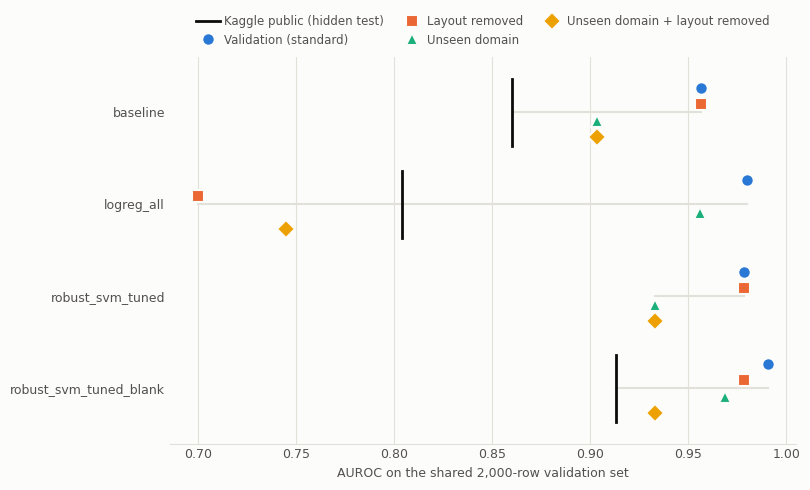

In [10]:
fig = plot_stress_summary(table)
savefig(fig, "joling_stress_summary");

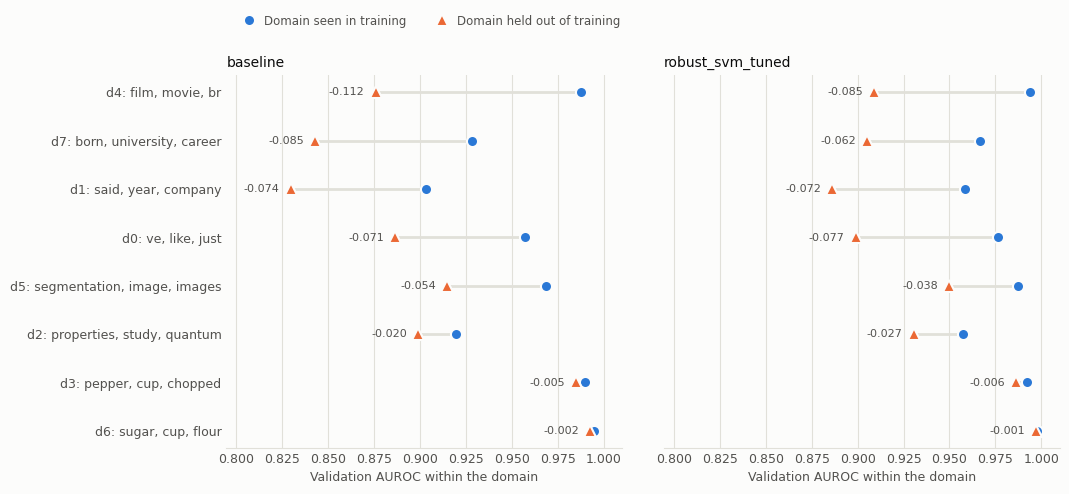

In [11]:
fig = plot_domain_drop({m: per_domain[m] for m in ["baseline", "robust_svm_tuned"]}, domains.names_)
savefig(fig, "joling_domain_drop");

## Step 4 · Does the answer depend on `k = 8`?
The number of topics is our choice, so we repeat the baseline test with 6 and 10 topics.

In [12]:
rows = [{"k": 8, **{c: base_summary[c] for c in ["val_auroc", "seen_domain_mean", "unseen_domain_mean"]}}]
for k in (6, 10):
    dk = TopicDomains(k=k).fit(train_df["text"])
    s, _, _ = domain_stress_test(lambda: make_model("baseline"), train_df, val_df,
                                 dk.predict(train_df["text"]), dk.predict(val_df["text"]), verbose=False)
    rows.append({"k": k, **{c: s[c] for c in ["val_auroc", "seen_domain_mean", "unseen_domain_mean"]}})
k_table = pd.DataFrame(rows).sort_values("k")
k_table.to_csv(RESULTS_DIR / "joling_domain_stress_k.csv", index=False)
k_table.round(4)

,k,val_auroc,seen_domain_mean,unseen_domain_mean
1,6,0.9563,0.9444,0.8741
0,8,0.9563,0.9562,0.9033
2,10,0.9563,0.9488,0.9058


## What we learned
1. The 0.99 on standard validation depends on two things the hidden test set does not give us: topics the model has
   already seen, and the layout habits of our training sources. Taking either away costs several points.
2. The topic effect is uneven. Recipes are easy even when unseen (0.99); film reviews, biographies, news and personal
   posts are where models lose the most. Three of those four (d0 personal posts, d1 news, d4 film reviews) are *more* common in
   `test.csv` than in `train.csv` (see the share table).
3. Layout features are the riskiest. `logreg_all` drops by 0.28 when line breaks are collapsed, and the blank-line boost
   (+0.012 on standard validation) adds nothing once layout is removed.

## Limits
- Our "domains" are k-means groups of words, a stand-in for real domain labels. The size of the drop depends on `k`
  (0.070 / 0.053 / 0.043 for k = 6 / 8 / 10), but it is there for every `k`.
- A held-out topic still comes from the same sources and the same AI generators as the training data. The real test set
  also has new generators and edited AI text, and it fits our topics worse than validation does (similarity 0.597 vs
  0.646). So the "unseen" numbers are probably still optimistic: 0.903 and 0.933 here, 0.860 and 0.913 on Kaggle.
- "Layout removed" is a worst case for layout features. Real test texts keep their layout, and the team's notes say the
  blank-line boost did help on Kaggle.
- The comparison with Kaggle uses three models and the public leaderboard (900 rows). Nothing was tuned on it.

## Next
`02`: a detector built on how *predictable* a text is to a small language model, instead of which words it contains.
It will be judged with the same four numbers as the models above.